# 📊 NGÀY 1: KHÁM PHÁ ĐỊNH LƯỢNG (QUANT EDA) & KIỂM CHỨNG 5 STYLIZED FACTS
### Đề tài: *Stock Movement Prediction & ML-Based Trading Strategy Backtesting*
**Mã cổ phiếu:** HPG (Tập đoàn Hòa Phát - Sàn HOSE, Việt Nam)  
**Khung thời gian:** 10 năm (2016-01-01 đến 2026-11-01)  
**Tần suất dữ liệu:** Daily (1D)  

---

## 🎯 Mục tiêu của Notebook này
Trong Machine Learning nói chung, EDA thường chỉ dừng lại ở việc xem dữ liệu có thiếu không hay phân phối ra sao. Nhưng trong **Quantitative Finance (Tài chính định lượng)**, EDA là bước **sống còn mang tính khoa học**, nhằm kiểm định xem chuỗi dữ liệu có thỏa mãn **5 Sự thật kinh điển (5 Stylized Facts)** của thị trường hay không:

1. **Fact 1 - Tính dừng (Stationarity):** Giá cổ phiếu không dừng ($Non-stationary$), nhưng Lợi suất ($Log Return$) bắt buộc phải dừng ($Stationary$) để tránh hiện tượng *Hồi quy ảo (Spurious Regression)* trong ML.
2. **Fact 2 - Phân phối Đuôi béo (Fat-Tails & Leptokurtic):** Lợi suất cổ phiếu không bao giờ tuân theo phân phối chuẩn Gaussian mà có đuôi béo và độ nhọn cao; kiểm định Jarque-Bera để nhận diện rủi ro "Thiên nga đen".
3. **Fact 3 - Tụ cụm biến động (Volatility Clustering) & Không có tự tương quan tuyến tính:** Thị trường hiệu quả yếu (lợi suất phiên hôm nay khó đoán qua phiên hôm trước), nhưng độ lớn biến động $|r_t|$ có "trí nhớ dài hạn" (sóng gió kéo theo sóng gió).
4. **Fact 4 - Vi cấu trúc sàn HOSE & Chi phí thực tế:** Biên độ trần/sàn $\pm 7\%$, chu kỳ thanh toán $T+2.5$, và tác động của phí giao dịch $0.45\%$ lên tỷ lệ nhãn thực tế ($RQ1$ vs $RQ2$).
5. **Fact 5 - Hồ ngập lụt Drawdown (Underwater Profile):** Bóc tách các đợt sụt giảm nghiêm trọng nhất trong 10 năm của HPG để hiểu khẩu vị rủi ro tối đa cần phòng ngừa khi làm Backtesting.


---
## 🛠️ Bước 0: Thiết lập Môi trường & Khai báo Thư viện
### Giải thích:
* Chúng ta cần các thư viện xử lý số liệu mạnh nhất: `pandas`, `numpy`, `scipy.stats`.
* Thư viện chuyên dụng kinh tế lượng: `statsmodels` (chứa các phép kiểm định ADF Test, Ljung-Box Test, biểu đồ ACF).
* Thiết lập giao diện đồ họa chuẩn học thuật (`seaborn-v0_8-whitegrid`, font size rõ ràng, độ phân giải cao).


In [1]:
import sys
from pathlib import Path

# Thêm thư mục gốc vào đường dẫn hệ thống để có thể import từ src/
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

# Cấu hình thẩm mỹ đồ thị
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print(f"✅ Môi trường đã sẵn sàng! Thư mục dự án: {project_root}")


✅ Môi trường đã sẵn sàng! Thư mục dự án: g:\AI_CODE4LIFE\My_Project\Machine_Learning\stock-ml-backtesting


---
## 📂 Bước 1: Nạp Dữ liệu 10 Năm HPG & Kiểm tra Tính Toàn vẹn (Sanity Check)

### Tại sao bước này quan trọng?
* Dữ liệu được nạp từ file `data/raw/HPG_10y_daily.parquet` (đã được trạm `data_loader.py` xử lý giá điều chỉnh - **Adjusted Price**).
* **Adjusted Price** đã khử hoàn toàn các cú sụt giá giả vào các ngày giao dịch không hưởng quyền khi HPG chia cổ tức bằng cổ phiếu (20-30%/năm).
* Chúng ta cần kiểm tra:
  * Số lượng phiên giao dịch hợp lệ.
  * Khoảng thời gian bắt đầu và kết thúc.
  * Các cột nến tiêu chuẩn: `open`, `high`, `low`, `close`, `volume`.


In [2]:
# Đọc file cấu hình config.yaml
config_path = project_root / "configs" / "config.yaml"
with open(config_path, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Đường dẫn file Parquet đã kéo về ở Bước Data Ingestion
raw_parquet_path = project_root / config["data"]["raw_parquet_path"]
df_raw = pd.read_parquet(raw_parquet_path)

print(f"📊 Tổng số phiên giao dịch 10 năm: {len(df_raw)} phiên")
print(f"⏳ Khung thời gian thực tế: từ {df_raw.index.min().strftime('%d/%m/%Y')} đến {df_raw.index.max().strftime('%d/%m/%Y')}")
print("\n5 phiên đầu tiên (Năm 2016):")
display(df_raw.head())
print("\n5 phiên gần nhất (Năm 2026):")
display(df_raw.tail())


📊 Tổng số phiên giao dịch 10 năm: 2639 phiên
⏳ Khung thời gian thực tế: từ 04/01/2016 đến 30/10/2026

5 phiên đầu tiên (Năm 2016):


Price,open,high,low,close,volume
date,,,,,
2016-01-04,2570.426883,2588.093129,2543.927734,2543.927734,4148213
2016-01-05,2535.094737,2552.760984,2517.428711,2517.428711,6447558
2016-01-06,2517.428600,2561.593994,2517.428600,2561.593994,6754883
2016-01-07,2526.261718,2535.094842,2482.096319,2490.929443,10563368
2016-01-08,2446.763672,2482.095941,2429.097427,2446.763672,8862778



5 phiên gần nhất (Năm 2026):


Price,open,high,low,close,volume
date,,,,,
2026-10-26,20950.0,21100.0,20900.0,20900.0,10478100
2026-10-27,20900.0,21200.0,20850.0,21000.0,9524500
2026-10-28,21100.0,21150.0,20750.0,20750.0,13204500
2026-10-29,20800.0,21600.0,20750.0,21200.0,36410800
2026-10-30,21250.0,21500.0,21000.0,21000.0,24773000


---
## 📐 Bước 2: Tính toán Chuỗi Lợi suất (Returns) & Biến Mục tiêu (Targets)

### Công thức Toán học:
1. **Lợi suất số học (Simple Return / Arithmetic Return):**
   $$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$
   * Dùng để đo lường tỷ lệ lãi/lỗ thực tế trong danh mục đầu tư.
2. **Lợi suất Logarit (Log Return / Continuously Compounded Return):**
   $$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) = \ln(P_t) - \ln(P_{t-1})$$
   * **Tại sao trong Quant luôn dùng Log Return?**
     * **Tính chất cộng dồn theo thời gian (Time-additivity):** Lợi suất 1 năm = tổng 252 ngày log return cộng lại: $r_{0 \to T} = \sum_{t=1}^T r_t$.
     * **Tính đối xứng:** Tăng 10% rồi giảm 10% theo log return sẽ về đúng điểm 0, trong khi simple return sẽ bị lệch âm.
     * Log return thường gần với phân phối chuẩn hơn giá thô.

### Tạo 2 biến mục tiêu giải quyết 2 câu hỏi nghiên cứu:
* **Target RQ1 (`target_direction`):** Dự đoán xu hướng phiên tiếp theo ($t+1$).
  $$y_t^{\text{RQ1}} = \begin{cases} 1 & \text{nếu } r_{t+1} > 0 \text{ (Phiên mai tăng)} \\ 0 & \text{nếu } r_{t+1} \le 0 \text{ (Phiên mai giảm/đứng giá)} \end{cases}$$
* **Target RQ2 (`target_net_profit`):** Dự đoán phiên mai tăng **vượt chi phí giao dịch** (Phí mua 0.15% + Phí bán 0.15% + Thuế bán 0.10% + Slippage 0.05% = $0.45\%$ hay 45 bps).
  $$y_t^{\text{RQ2}} = \begin{cases} 1 & \text{nếu } r_{t+1} > 0.0045 \\ 0 & \text{ngược lại} \end{cases}$$


In [3]:
df = df_raw.copy()

# 1. Tính toán Lợi suất hàng ngày
df["simple_return"] = df["close"].pct_change()
df["log_return"] = np.log(df["close"] / df["close"].shift(1))

# 2. Tạo biến mục tiêu cho phiên ngày mai (t+1) bằng cách shift(-1)
df["next_log_return"] = df["log_return"].shift(-1)
df["target_direction"] = (df["next_log_return"] > 0).astype(int)

# 3. Tạo biến mục tiêu kinh tế (vượt phí giao dịch 0.45%)
round_trip_cost = config["market_microstructure"]["round_trip_cost"] # 0.0045
df["target_net_profit"] = (df["next_log_return"] > round_trip_cost).astype(int)

# Loại bỏ dòng đầu tiên (do pct_change bị NaN) và dòng cuối cùng (do shift(-1) chưa có ngày mai)
df = df.dropna().copy()

print(f"✅ Đã tạo features & targets thành công. Số mẫu sạch đưa vào phân tích: {len(df)} phiên.")
display(df[["close", "simple_return", "log_return", "next_log_return", "target_direction", "target_net_profit"]].head())


✅ Đã tạo features & targets thành công. Số mẫu sạch đưa vào phân tích: 2637 phiên.


Price,close,simple_return,log_return,next_log_return,target_direction,target_net_profit
date,,,,,,
2016-01-05,2517.428711,-0.010417,-0.010471,0.017392,1,1
2016-01-06,2561.593994,0.017544,0.017392,-0.027974,0,0
2016-01-07,2490.929443,-0.027586,-0.027974,-0.017890,0,0
2016-01-08,2446.763672,-0.017731,-0.017890,0.000000,0,0
2016-01-11,2446.763672,0.000000,0.000000,0.010772,1,1


---
## 📉 Bước 3: Phân tích Đồ thị Giá & "Hồ ngập lụt" Drawdown Profile (10 Năm HPG)

### Cách đọc biểu đồ Underwater Drawdown:
* **Công thức Drawdown tại ngày $t$:**
  $$DD_t = \frac{P_t - \max_{\tau \le t}(P_\tau)}{\max_{\tau \le t}(P_\tau)}$$
* $DD_t$ luôn $\le 0$. Khi tài sản đang ở đỉnh cao nhất lịch sử (All-Time High), $DD_t = 0\%$.
* Khi thị trường sập, đồ thị sẽ chìm sâu xuống dưới mặt nước ("Underwater").
* **Maximum Drawdown (MDD):** Đáy sâu nhất của đồ thị này trong 10 năm. Đây là thước đo rủi ro lớn nhất mà bất kỳ chiến lược giao dịch định lượng nào cũng phải tìm cách giảm thiểu so với việc Buy & Hold.


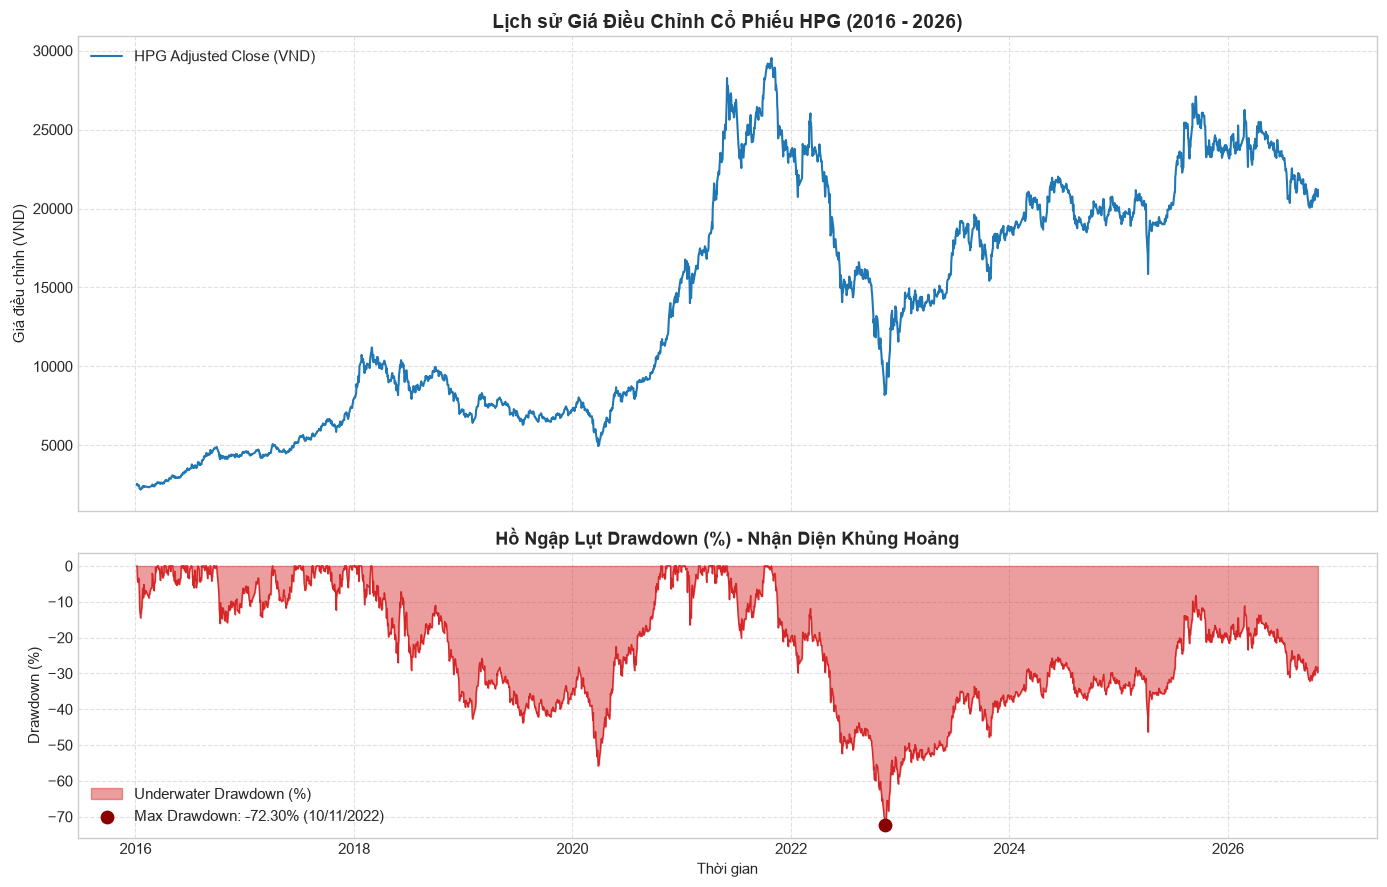

⚠️ Maximum Drawdown (MDD) của HPG: -72.30% rơi vào ngày 10/11/2022.
👉 Nhận xét: Trong đợt sập ngành thép năm 2022, HPG từng mất hơn một nửa giá trị từ đỉnh!
   Nhiệm vụ của ML Trading Strategy (RQ2) là phải nhận diện tín hiệu thoát hàng để tránh cú sụt hầm này.


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})

# Đồ thị 1: Giá đóng cửa điều chỉnh 10 năm của HPG
axes[0].plot(df.index, df["close"], color="#1f77b4", linewidth=1.5, label="HPG Adjusted Close (VND)")
axes[0].set_title("Lịch sử Giá Điều Chỉnh Cổ Phiếu HPG (2016 - 2026)", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Giá điều chỉnh (VND)")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Đồ thị 2: Underwater Drawdown
rolling_max = df["close"].cummax()
drawdown = (df["close"] - rolling_max) / rolling_max * 100
mdd = drawdown.min()
mdd_date = drawdown.idxmin()

axes[1].fill_between(df.index, drawdown, 0, color="#d62728", alpha=0.45, label="Underwater Drawdown (%)")
axes[1].plot(df.index, drawdown, color="#d62728", linewidth=1.0)
axes[1].scatter([mdd_date], [mdd], color="darkred", s=80, zorder=5, 
                label=f"Max Drawdown: {mdd:.2f}% ({mdd_date.strftime('%d/%m/%Y')})")
axes[1].set_title("Hồ Ngập Lụt Drawdown (%) - Nhận Diện Khủng Hoảng", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Thời gian")
axes[1].legend(loc="lower left")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

print(f"⚠️ Maximum Drawdown (MDD) của HPG: {mdd:.2f}% rơi vào ngày {mdd_date.strftime('%d/%m/%Y')}.")
print("👉 Nhận xét: Trong đợt sập ngành thép năm 2022, HPG từng mất hơn một nửa giá trị từ đỉnh!")
print("   Nhiệm vụ của ML Trading Strategy (RQ2) là phải nhận diện tín hiệu thoát hàng để tránh cú sụt hầm này.")


---
## 🧪 Bước 4: Kiểm chứng [FACT 1] - Tính Dừng (Stationarity) & ADF Test

### Cơ sở Toán học & Kinh tế lượng:
* Một chuỗi thời gian được gọi là **Dừng (Stationary)** nếu các đặc trưng thống kê của nó (Kỳ vọng $\mathbb{E}[X_t]$, Phương sai $\text{Var}(X_t)$, và Tự hiệp phương sai $\text{Cov}(X_t, X_{t+k})$) **không thay đổi theo thời gian**.
* **Kiểm định Augmented Dickey-Fuller (ADF Test):**
  * $H_0$ (Giả thuyết vô hiệu): Chuỗi có chứa nghiệm đơn vị (Unit Root) $\rightarrow$ **Không dừng (Non-stationary)**.
  * $H_1$: Chuỗi **Dừng (Stationary)**.
  * Nếu $p\text{-value} < 0.05$: Bác bỏ $H_0$, kết luận chuỗi có tính dừng.

### ⚠️ Hiểm họa "Hồi quy ảo" (Spurious Regression) trong ML:
* Nếu bạn đưa trực tiếp giá đóng cửa ($P_t$) vào huấn luyện mô hình Machine Learning, do giá có xu hướng tăng/giảm dài hạn (Trend), mô hình sẽ học vẹt các giá trị số tuyệt đối thay vì học quy luật động học.
* **Nguyên tắc bất biến:** Input của mô hình ML tài chính **phải là chuỗi dừng** (như Log Return, RSI, MACD, Normalized indicators), tuyệt đối không dùng giá thô!


In [5]:
# Chạy ADF Test cho Giá đóng cửa thô
adf_close = adfuller(df["close"])
# Chạy ADF Test cho Chuỗi Log Return
adf_ret = adfuller(df["log_return"])

adf_results = pd.DataFrame({
    "Chuỗi dữ liệu": ["Giá đóng cửa (Close)", "Lợi suất Log (Log Return)"],
    "ADF Statistic": [f"{adf_close[0]:.4f}", f"{adf_ret[0]:.4f}"],
    "p-value": [f"{adf_close[1]:.4f}", f"{adf_ret[1]:.4e}"],
    "Số Lags sử dụng": [adf_close[2], adf_ret[2]],
    "Số quan sát": [adf_close[3], adf_ret[3]],
    "Ngưỡng 1%": [f"{adf_close[4]['1%']:.4f}", f"{adf_ret[4]['1%']:.4f}"],
    "Ngưỡng 5%": [f"{adf_close[4]['5%']:.4f}", f"{adf_ret[4]['5%']:.4f}"],
    "Kết luận Thống kê": [
        "❌ KHÔNG DỪNG (p > 0.05)",
        "✅ DỪNG TUYỆT ĐỐI (p < 0.0001)"
    ]
})

display(adf_results)
print("\n💡 Ý NGHĨA QUAN TRỌNG:")
print(f"1. Giá Close có p-value = {adf_close[1]:.4f} > 0.05 -> Chứa Unit Root, không dừng.")
print(f"2. Log Return có p-value = {adf_ret[1]:.2e} << 0.05 và ADF Stat = {adf_ret[0]:.2f} nhỏ hơn xa ngưỡng 1% ({adf_ret[4]['1%']:.2f}).")
print("-> Bằng chứng thép xác nhận Log Return là stationary, hoàn toàn hợp lệ làm đầu vào cho ML!")


C:\Users\My laptop\AppData\Local\Temp\ipykernel_29228\1165140116.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_close = adfuller(df["close"])
C:\Users\My laptop\AppData\Local\Temp\ipykernel_29228\1165140116.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_ret = adfuller(df["log_return"])


,Chuỗi dữ liệu,ADF Statistic,p-value,Số Lags sử dụng,Số quan sát,Ngưỡng 1%,Ngưỡng 5%,Kết luận Thống kê
0,Giá đóng cửa (Close),-1.3913,0.5864,2,2634,-3.4328,-2.8626,❌ KHÔNG DỪNG (p > 0.05)
1,Lợi suất Log (Log Return),-50.0257,0.0000e+00,0,2636,-3.4328,-2.8626,✅ DỪNG TUYỆT ĐỐI (p < 0.0001)



💡 Ý NGHĨA QUAN TRỌNG:
1. Giá Close có p-value = 0.5864 > 0.05 -> Chứa Unit Root, không dừng.
2. Log Return có p-value = 0.00e+00 << 0.05 và ADF Stat = -50.03 nhỏ hơn xa ngưỡng 1% (-3.43).
-> Bằng chứng thép xác nhận Log Return là stationary, hoàn toàn hợp lệ làm đầu vào cho ML!


---
## 🔔 Bước 5: Kiểm chứng [FACT 2] - Phân phối Đuôi béo (Fat Tails) & Kiểm định Normality

### Tại sao thị trường không phải là "Phân phối chuẩn Gaussian"?
Trong tài chính cổ điển (như mô hình Black-Scholes), người ta thường giả định lợi suất tuân theo phân phối chuẩn hình chuông. Nhưng thực tế thị trường chứng khoán luôn có **4 Moments thống kê**:

1. **Mean (Kỳ vọng):** $\mu = \mathbb{E}[r_t]$.
2. **Variance (Phương sai) / Volatility:** $\sigma = \sqrt{\mathbb{E}[(r_t - \mu)^2]}$.
3. **Skewness (Độ lệch):** Đo lường tính bất đối xứng của phân phối.
   * Skewness $< 0$ (Lệch âm): Đuôi bên trái dài hơn $\rightarrow$ Số lần sập mạnh nhiều hơn và khốc liệt hơn số lần tăng sốc.
4. **Kurtosis (Độ nhọn đuôi béo - Excess Kurtosis):**
   * Phân phối chuẩn có Kurtosis $= 3$ (Excess Kurtosis $= 0$).
   * Nếu Excess Kurtosis $> 0$ $\rightarrow$ **Leptokurtic (Đuôi béo)**: Các biến cố cực đoan (kịch trần/sàn) xảy ra với tần suất cao gấp nhiều lần so với lý thuyết thông thường.
5. **Kiểm định Jarque-Bera:** Kiểm tra xem dữ liệu có đồng thời thỏa mãn Skewness $= 0$ và Excess Kurtosis $= 0$ hay không.


,Chỉ số thống kê,Giá trị,Ý nghĩa định lượng
0,Lợi suất trung bình ngày (Daily Mean),0.0804%,Lợi nhuận bình quân mỗi phiên giao dịch
1,Lợi suất kỳ vọng năm (Annualized Return),20.26%,Tỷ suất sinh lời kép ấn tượng của HPG trong 10...
2,Độ biến động ngày (Daily Volatility),2.0725%,Biên độ dao động trung bình 1 phiên
3,Độ biến động hàng năm (Annualized Volatility),32.90%,Đặc trưng cổ phiếu chu kỳ cao (High Beta)
4,Độ lệch (Skewness),-0.0419,Lệch âm: Rủi ro sập đột ngột cao hơn tăng sốc
5,Độ nhọn đuôi béo (Excess Kurtosis),2.3064,Rất lớn (>0): Đuôi béo Leptokurtic cực rõ rệt
6,Jarque-Bera Test Statistic,581.89,Thước đo khoảng cách với phân phối chuẩn
7,Jarque-Bera p-value,4.4174e-127,Bác bỏ tuyệt đối giả thuyết phân phối chuẩn Ga...


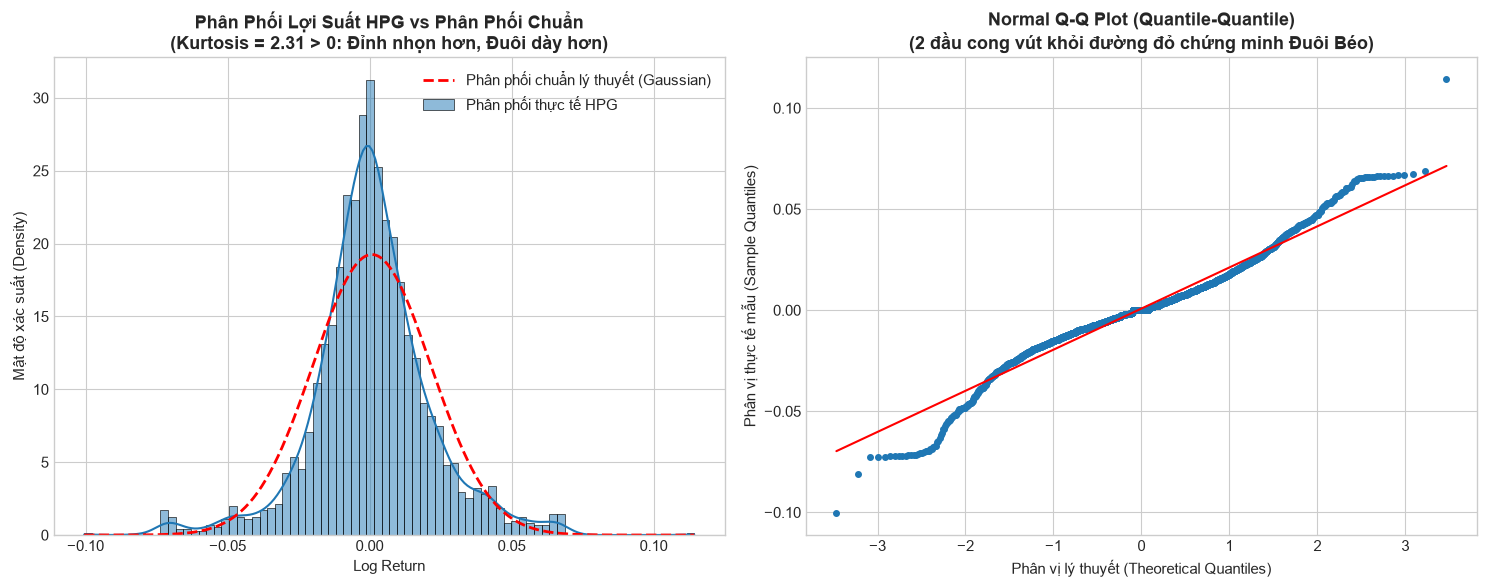

In [6]:
ret = df["log_return"]

mean_d = ret.mean()
mean_ann = mean_d * 252 # Chuẩn hóa 252 ngày giao dịch/năm
vol_d = ret.std()
vol_ann = vol_d * np.sqrt(252)
skewness = ret.skew()
kurt = ret.kurtosis() # Pandas tự động tính Excess Kurtosis (so với 0 của Normal)
jb_stat, jb_pval = stats.jarque_bera(ret)

# Bảng tổng hợp thống kê
moments_df = pd.DataFrame({
    "Chỉ số thống kê": [
        "Lợi suất trung bình ngày (Daily Mean)",
        "Lợi suất kỳ vọng năm (Annualized Return)",
        "Độ biến động ngày (Daily Volatility)",
        "Độ biến động hàng năm (Annualized Volatility)",
        "Độ lệch (Skewness)",
        "Độ nhọn đuôi béo (Excess Kurtosis)",
        "Jarque-Bera Test Statistic",
        "Jarque-Bera p-value"
    ],
    "Giá trị": [
        f"{mean_d*100:.4f}%",
        f"{mean_ann*100:.2f}%",
        f"{vol_d*100:.4f}%",
        f"{vol_ann*100:.2f}%",
        f"{skewness:.4f}",
        f"{kurt:.4f}",
        f"{jb_stat:.2f}",
        f"{jb_pval:.4e}"
    ],
    "Ý nghĩa định lượng": [
        "Lợi nhuận bình quân mỗi phiên giao dịch",
        "Tỷ suất sinh lời kép ấn tượng của HPG trong 10 năm",
        "Biên độ dao động trung bình 1 phiên",
        "Đặc trưng cổ phiếu chu kỳ cao (High Beta)",
        "Lệch âm: Rủi ro sập đột ngột cao hơn tăng sốc",
        "Rất lớn (>0): Đuôi béo Leptokurtic cực rõ rệt",
        "Thước đo khoảng cách với phân phối chuẩn",
        "Bác bỏ tuyệt đối giả thuyết phân phối chuẩn Gaussian"
    ]
})

display(moments_df)

# Vẽ biểu đồ Histogram phân phối thực tế so với Phân phối chuẩn lý thuyết & Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Histogram + Đường cong KDE
sns.histplot(ret, bins=80, kde=True, stat="density", color="#1f77b4", ax=axes[0], label="Phân phối thực tế HPG")
# Vẽ thêm đường cong chuẩn lý thuyết có cùng Mean & Std
x_range = np.linspace(ret.min(), ret.max(), 300)
norm_pdf = stats.norm.pdf(x_range, loc=mean_d, scale=vol_d)
axes[0].plot(x_range, norm_pdf, "r--", linewidth=2.0, label="Phân phối chuẩn lý thuyết (Gaussian)")
axes[0].set_title(f"Phân Phối Lợi Suất HPG vs Phân Phối Chuẩn\n(Kurtosis = {kurt:.2f} > 0: Đỉnh nhọn hơn, Đuôi dày hơn)", fontweight="bold")
axes[0].set_xlabel("Log Return")
axes[0].set_ylabel("Mật độ xác suất (Density)")
axes[0].legend()

# Subplot 2: Normal Q-Q Plot
stats.probplot(ret, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color("#1f77b4")
axes[1].get_lines()[0].set_markersize(4.0)
axes[1].get_lines()[1].set_color("red")
axes[1].set_title("Normal Q-Q Plot (Quantile-Quantile)\n(2 đầu cong vút khỏi đường đỏ chứng minh Đuôi Béo)", fontweight="bold")
axes[1].set_xlabel("Phân vị lý thuyết (Theoretical Quantiles)")
axes[1].set_ylabel("Phân vị thực tế mẫu (Sample Quantiles)")

plt.tight_layout()
plt.show()


---
## 🌊 Bước 6: Kiểm chứng [FACT 3] - Tụ Cụm Biến Động (Volatility Clustering) & Tự Tương Quan

### Hai phát hiện cốt lõi của Robert Engle (Nobel Kinh tế 2003):
1. **Chuỗi lợi suất $r_t$ gần như không có tự tương quan tuyến tính (No Linear Autocorrelation):**
   * Nếu bạn biết hôm nay giá tăng $+2\%$, bạn **không thể** dùng công thức tuyến tính đơn giản để bảo ngày mai chắc chắn tăng $+2\%$. Đây là biểu hiện của **Giả thuyết Thị trường Hiệu quả dạng yếu (Weak-form EMH)**.
2. **Nhưng chuỗi giá trị tuyệt đối $|r_t|$ hoặc bình phương $r_t^2$ lại có tự tương quan cực kỳ mạnh (Volatility Memory):**
   * *"Sóng lớn kéo theo sóng lớn, ngày yên ả nối tiếp ngày yên ả"*. Khi thị trường bắt đầu chao đảo, các phiên tiếp theo cũng sẽ có biên độ dao động rất lớn.
   * Đây chính là cơ sở ra đời của các mô hình ARCH/GARCH và là **mảnh đất màu mỡ để các mô hình Machine Learning / Deep Learning khai thác quy luật biến động (Alpha)**!

### Kiểm định Ljung-Box:
* $H_0$: Dữ liệu không có tự tương quan (White Noise).
* Nếu $p\text{-value} < 0.05$: Bác bỏ $H_0$, xác nhận có tương quan chuỗi qua các độ trễ (lags).


,Lags,p-value trên r_t (Lợi suất),Kết luận r_t,p-value trên |r_t| (Độ lớn biến động),Kết luận |r_t|
0,5,0.6692,Không tự tương quan (White Noise),4.6751e-71,TỤ CỤM BIẾN ĐỘNG CỰC MẠNH (p << 0.01)
1,10,0.9047,Không tự tương quan (White Noise),1.1448e-104,TỤ CỤM BIẾN ĐỘNG CỰC MẠNH (p << 0.01)
2,20,0.4918,Không tự tương quan (White Noise),2.7980e-144,TỤ CỤM BIẾN ĐỘNG CỰC MẠNH (p << 0.01)


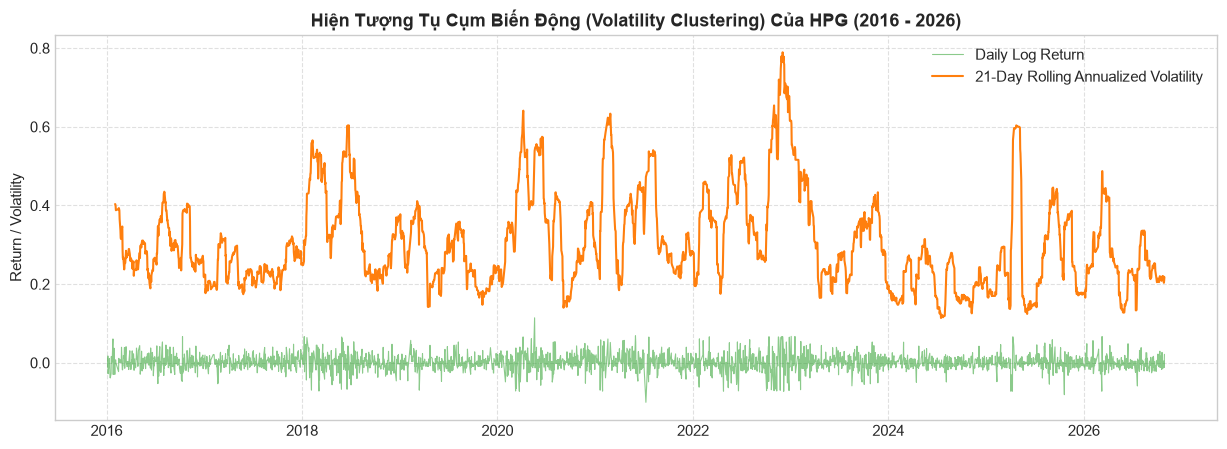

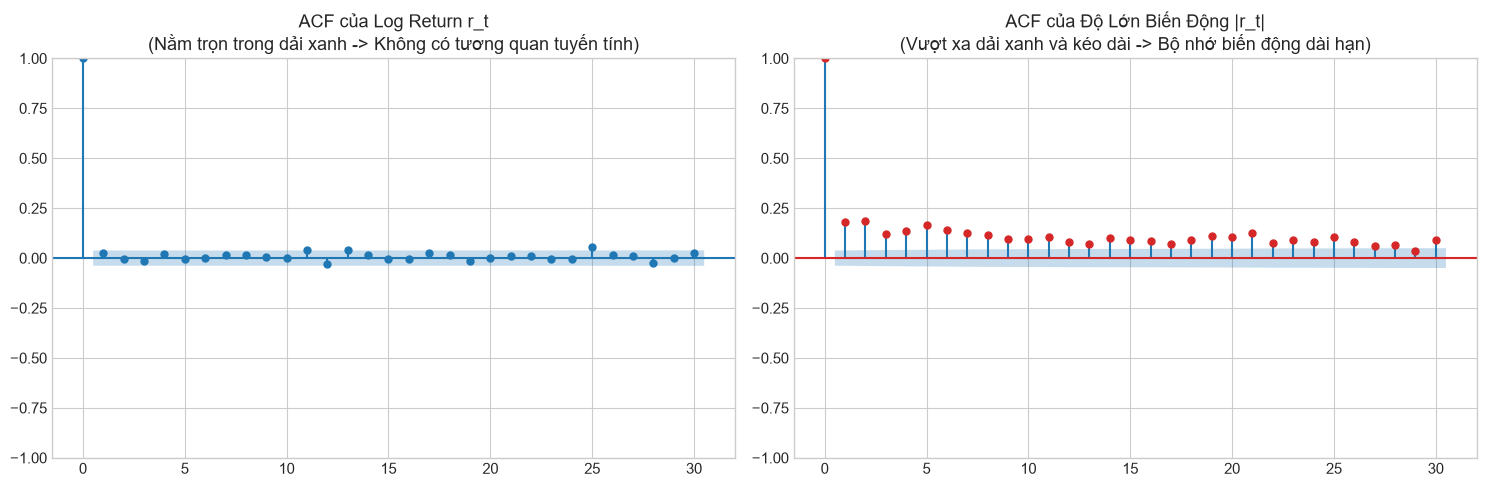

In [7]:
# Kiểm định Ljung-Box trên chuỗi lợi suất r_t
lb_ret = acorr_ljungbox(ret, lags=[5, 10, 20], return_df=True)
# Kiểm định Ljung-Box trên chuỗi độ lớn biến động |r_t|
lb_abs_ret = acorr_ljungbox(ret.abs(), lags=[5, 10, 20], return_df=True)

lb_comparison = pd.DataFrame({
    "Lags": [5, 10, 20],
    "p-value trên r_t (Lợi suất)": [f"{p:.4f}" for p in lb_ret["lb_pvalue"]],
    "Kết luận r_t": ["Không tự tương quan (White Noise)" if p > 0.05 else "Có tương quan" for p in lb_ret["lb_pvalue"]],
    "p-value trên |r_t| (Độ lớn biến động)": [f"{p:.4e}" for p in lb_abs_ret["lb_pvalue"]],
    "Kết luận |r_t|": ["TỤ CỤM BIẾN ĐỘNG CỰC MẠNH (p << 0.01)" if p < 0.01 else "Không" for p in lb_abs_ret["lb_pvalue"]]
})

display(lb_comparison)

# 1. Vẽ đồ thị chuỗi thời gian Log Return & Dải biến động lăn 21 phiên (1 tháng)
plt.figure(figsize=(15, 5))
plt.plot(df.index, df["log_return"], color="#2ca02c", alpha=0.55, linewidth=0.8, label="Daily Log Return")
rolling_vol = df["log_return"].rolling(window=21).std() * np.sqrt(252) * 100
plt.plot(df.index, rolling_vol / 100, color="#ff7f0e", linewidth=1.5, label="21-Day Rolling Annualized Volatility")
plt.title("Hiện Tượng Tụ Cụm Biến Động (Volatility Clustering) Của HPG (2016 - 2026)", fontsize=13, fontweight="bold")
plt.ylabel("Return / Volatility")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 2. Vẽ biểu đồ Tự tương quan ACF (Autocorrelation Function)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_acf(df["log_return"], lags=30, ax=axes[0], color="#1f77b4", title="ACF của Log Return r_t\n(Nằm trọn trong dải xanh -> Không có tương quan tuyến tính)")
plot_acf(df["log_return"].abs(), lags=30, ax=axes[1], color="#d62728", title="ACF của Độ Lớn Biến Động |r_t|\n(Vượt xa dải xanh và kéo dài -> Bộ nhớ biến động dài hạn)")
plt.tight_layout()
plt.show()


---
## ⚖️ Bước 7: Phân tích [FACT 4] - Vi Cấu Trúc Sàn HOSE & Tỷ Lệ Nhãn Thực Tế ($RQ1$ vs $RQ2$)

### Đặc thù sàn HOSE cần ghi nhớ:
1. **Biên độ trần/sàn $\pm 7\%$:** Giá không thể vượt khỏi ngưỡng này trong 1 phiên. Các phiên biến động $\ge 6.7\%$ thường là kịch trần hoặc trắng sàn bên bán, thanh khoản bị nghẽn.
2. **Chi phí giao dịch thực tế ($45$ bps hay $0.45\%$):**
   * Phí môi giới mua: $0.15\%$
   * Phí môi giới bán: $0.15\%$
   * Thuế TNCN khi bán: $0.10\%$
   * Slippage (trượt giá): $0.05\%$
3. **So sánh tỷ lệ nhãn:**
   * **Chiến lược ngây thơ (Always-Long - RQ1):** Chỉ cần ngày mai giá tăng ($>0$) là thắng $\rightarrow$ Đạt bao nhiêu %?
   * **Chiến lược thực chiến sau thuế phí (RQ2):** Ngày mai phải tăng $> 0.45\%$ mới có lãi ròng $\rightarrow$ Đạt bao nhiêu %?


🏛️ THỐNG KÊ VI CẤU TRÚC SÀN HOSE:
  - Số phiên kịch trần (>= +6.7%) : 19 phiên
  - Số phiên sập sàn   (<= -6.7%) : 21 phiên
  - Tổng số phiên chạm giới hạn biên độ: 40 phiên trong 10 năm.

🎯 TỶ LỆ NHÃN MỤC TIÊU:
  - Tỷ lệ phiên tăng giá (RQ1 - Target Direction = 1) : 46.95% (Tỷ lệ giảm: 53.05%)
  - Tỷ lệ phiên tăng vượt phí (RQ2 - Net Profit = 1)   : 38.07%


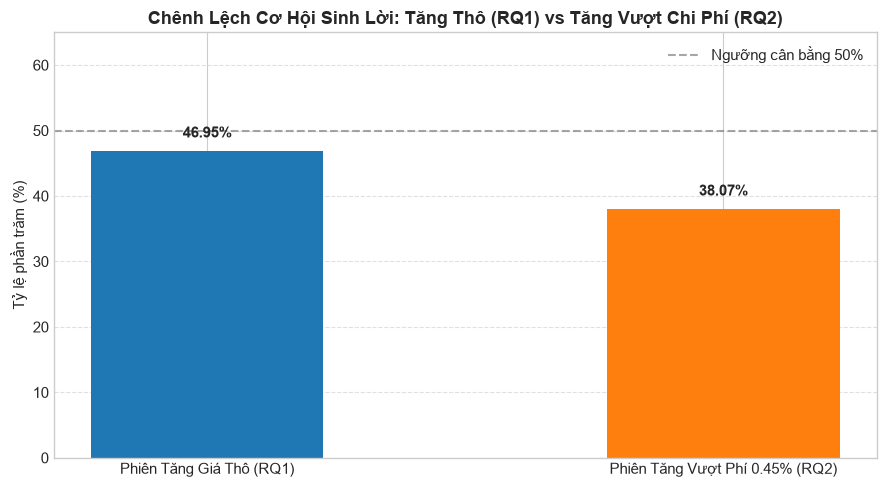


⚠️ BÀI TOÁN KINH TẾ (ECONOMIC REALITY):
-> Khi tính thêm 0.45% chi phí giao dịch, số phiên sinh lời thực tế giảm từ 46.95% xuống chỉ còn 38.07%!
-> Nghĩa là: Nếu vào lệnh ngẫu nhiên, bạn chỉ có ~38% cơ hội kiếm được tiền.
-> Mô hình Machine Learning muốn sinh lời trên thực tế (RQ2) bắt buộc phải đạt độ tin cậy cao để bù đắp 45 bps này!


In [8]:
# Đếm số phiên kịch trần/sàn
limit_threshold = config["market_microstructure"]["limit_hit_threshold"] # 0.067 (6.7%)
ceil_sessions = (df["simple_return"] >= limit_threshold).sum()
floor_sessions = (df["simple_return"] <= -limit_threshold).sum()
total_limit_hits = ceil_sessions + floor_sessions

# Tỷ lệ nhãn
up_ratio = df["target_direction"].mean() * 100
down_ratio = 100 - up_ratio
net_profit_ratio = df["target_net_profit"].mean() * 100

print(f"🏛️ THỐNG KÊ VI CẤU TRÚC SÀN HOSE:")
print(f"  - Số phiên kịch trần (>= +6.7%) : {ceil_sessions} phiên")
print(f"  - Số phiên sập sàn   (<= -6.7%) : {floor_sessions} phiên")
print(f"  - Tổng số phiên chạm giới hạn biên độ: {total_limit_hits} phiên trong 10 năm.")

print(f"\n🎯 TỶ LỆ NHÃN MỤC TIÊU:")
print(f"  - Tỷ lệ phiên tăng giá (RQ1 - Target Direction = 1) : {up_ratio:.2f}% (Tỷ lệ giảm: {down_ratio:.2f}%)")
print(f"  - Tỷ lệ phiên tăng vượt phí (RQ2 - Net Profit = 1)   : {net_profit_ratio:.2f}%")

# Vẽ biểu đồ cột trực quan hóa chênh lệch tỷ lệ nhãn
plt.figure(figsize=(9, 5))
categories = ["Phiên Tăng Giá Thô (RQ1)", "Phiên Tăng Vượt Phí 0.45% (RQ2)"]
values = [up_ratio, net_profit_ratio]
colors = ["#1f77b4", "#ff7f0e"]

bars = plt.bar(categories, values, color=colors, width=0.45)
plt.axhline(50, color="gray", linestyle="--", alpha=0.7, label="Ngưỡng cân bằng 50%")
plt.ylabel("Tỷ lệ phần trăm (%)")
plt.title("Chênh Lệch Cơ Hội Sinh Lời: Tăng Thô (RQ1) vs Tăng Vượt Chi Phí (RQ2)", fontsize=13, fontweight="bold")
plt.ylim(0, 65)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\n⚠️ BÀI TOÁN KINH TẾ (ECONOMIC REALITY):")
print(f"-> Khi tính thêm 0.45% chi phí giao dịch, số phiên sinh lời thực tế giảm từ {up_ratio:.2f}% xuống chỉ còn {net_profit_ratio:.2f}%!")
print("-> Nghĩa là: Nếu vào lệnh ngẫu nhiên, bạn chỉ có ~38% cơ hội kiếm được tiền.")
print("-> Mô hình Machine Learning muốn sinh lời trên thực tế (RQ2) bắt buộc phải đạt độ tin cậy cao để bù đắp 45 bps này!")


---
## 🏆 BÀI HỌC RÚT RA TỪ NGÀY 1 & CHUẨN BỊ CHO NGÀY 2

Sau khi hoàn thành Quant EDA trên dữ liệu 10 năm của cổ phiếu HPG, chúng ta rút ra **4 nguyên lý cốt tử** cho các bước xây dựng mô hình tiếp theo:

1. **Chuỗi dữ liệu đầu vào:** Tuyệt đối không dùng giá đóng cửa thô ($P_t$) vì vi phạm tính dừng ($p = 0.5864$). Toàn bộ feature engineering ở Ngày 2 phải dựa trên **Log Returns**, **Tỷ số biến động (Rolling Ratios)**, và **Chỉ báo kỹ thuật đã chuẩn hóa (Bounded Indicators như RSI, ATR, Z-Score)**.
2. **Không ảo tưởng về phân phối chuẩn:** HPG có Excess Kurtosis lên tới $2.31$ và phân phối lệch âm. Các mô hình quản trị rủi ro sau này cần dùng **VaR 99% / Expected Shortfall (CVaR)** thay vì chỉ nhìn vào độ lệch chuẩn $\sigma$.
3. **Khai thác Volatility Clustering:** Biến động có tính trí nhớ dài hạn ($p < 0.0001$). Các đặc trưng độ biến động trượt (21 ngày, 63 ngày) và khối lượng đột biến (Volume Z-Score) sẽ là nguồn trích xuất tín hiệu quan trọng.
4. **Ngưỡng quyết định giao dịch (Decision Threshold):** Do chi phí vòng quay là $0.45\%$, một mô hình dự đoán xác suất ngây thơ tại ngưỡng $0.50$ sẽ bị bào mòn vốn. Trong file `config.yaml`, chúng ta đã thiết lập `prob_threshold_long: 0.53` để chỉ kích hoạt lệnh khi mô hình thực sự tự tin!

---
**Chúc mừng bạn đã hoàn thành phân tích Ngày 1! Hãy sẵn sàng cho Ngày 2: Feature Engineering & Purged Walk-Forward Validation!** 🚀
